<center><h1>Niu_Qiyu_HW5</h1></center>

**Name:** Qiyu Niu  
**GitHub Username:** QiyuNiu  
**USC ID:** 6184595941

## 1. Decision Trees as Interpretable Models

### (a) Obtain Data

The Acute Inflammations data has six predictors and two diagnosis columns. I use
the label powerset idea by combining the two diagnoses into one four-class label.
This keeps both answers together in one decision tree.

### Imports

In [19]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, Lasso
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import (
    GridSearchCV, StratifiedKFold, cross_val_score
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree, _tree
from xgboost import XGBRegressor

RANDOM_SEED = 552 # for reproducibility
DATA_DIR = Path("../data")

In [20]:
diagnosis_columns = [
    "temperature", "nausea", "lumbar_pain", "urine_pushing",
    "micturition_pains", "burning_urethra",
    "bladder_inflammation", "nephritis"
]

diagnosis = pd.read_csv(
    DATA_DIR / "diagnosis.data", sep="\t", header=None,
    names=diagnosis_columns, encoding="utf-16", decimal=","
)

X_diagnosis = diagnosis.iloc[:, :6].copy()
for column in X_diagnosis.columns[1:]:
    X_diagnosis[column] = X_diagnosis[column].map({"no": 0, "yes": 1})

y_diagnosis = (
    "Bladder: " + diagnosis["bladder_inflammation"]
    + ", Nephritis: " + diagnosis["nephritis"]
)

display(diagnosis.head())
print("Data shape:", diagnosis.shape)
display(y_diagnosis.value_counts().rename("count").to_frame())

,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,bladder_inflammation,nephritis
0,35.5,no,yes,no,no,no,no,no
1,35.9,no,no,yes,yes,yes,yes,no
2,35.9,no,yes,no,no,no,no,no
3,36.0,no,no,yes,yes,yes,yes,no
4,36.0,no,yes,no,no,no,no,no


Data shape: (120, 8)


,count
"Bladder: yes, Nephritis: no",40
"Bladder: no, Nephritis: yes",31
"Bladder: no, Nephritis: no",30
"Bladder: yes, Nephritis: yes",19


The temperature column is read with a comma decimal mark. For the five yes/no
predictors, 0 means no and 1 means yes. The four target classes cover every
possible pair of diagnoses that appears in the data.

### (b) Build a Decision Tree

Training accuracy: 1.000
Depth: 4
Number of leaves: 6


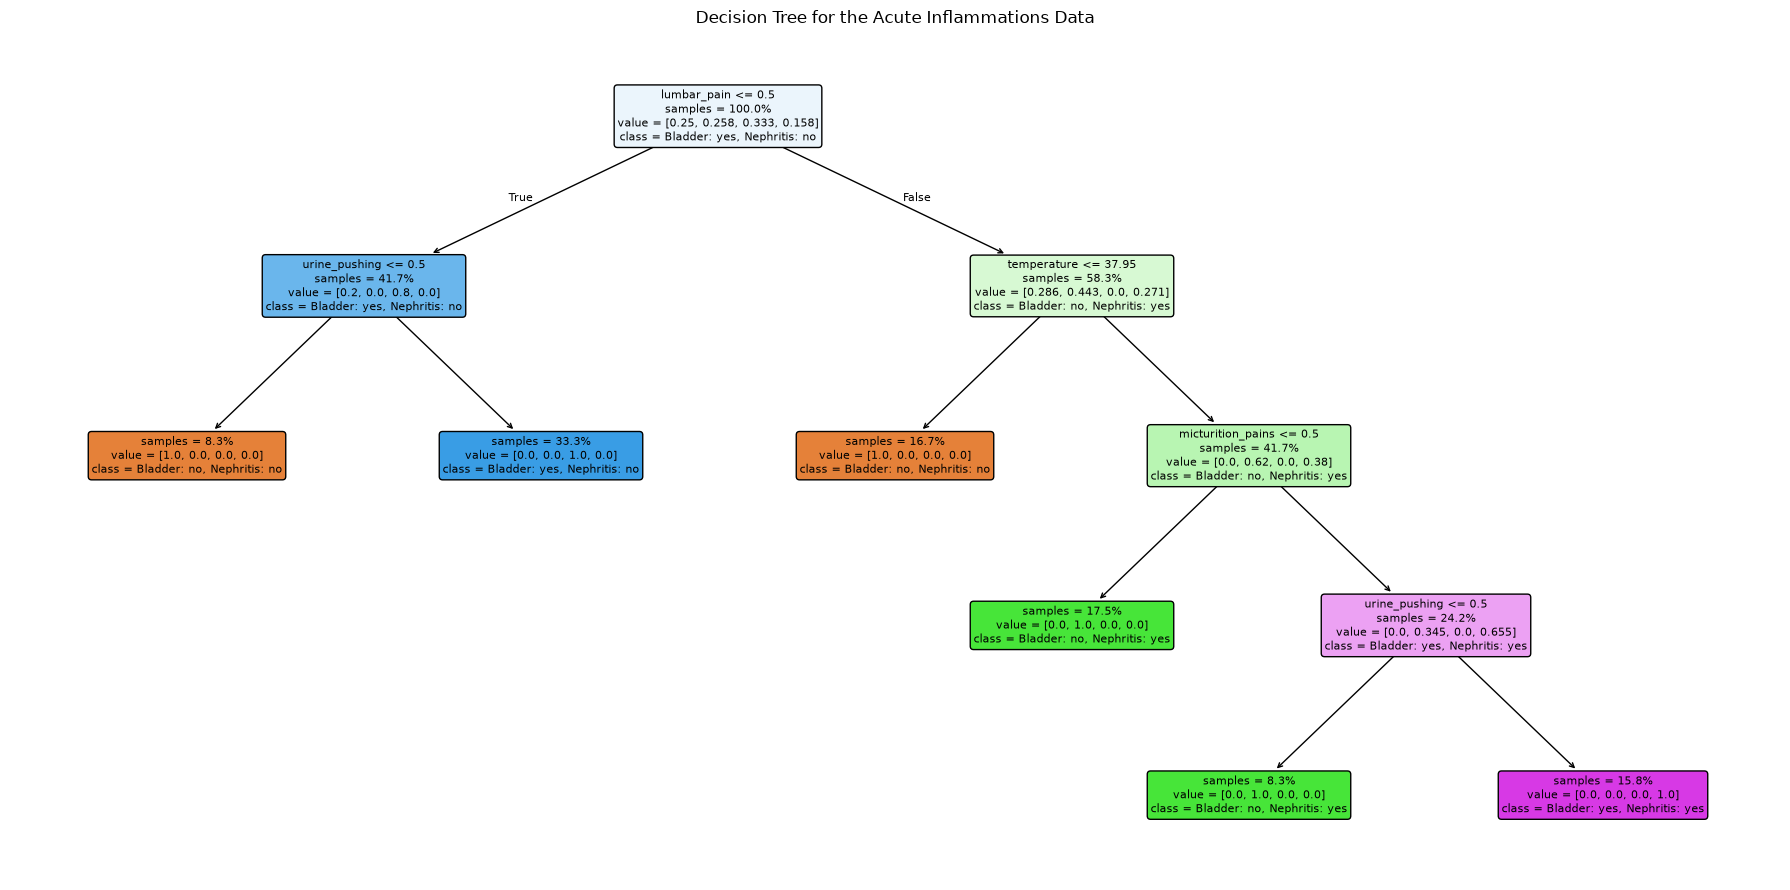

In [21]:
full_tree = DecisionTreeClassifier(random_state=RANDOM_SEED)
full_tree.fit(X_diagnosis, y_diagnosis)

print(f"Training accuracy: {full_tree.score(X_diagnosis, y_diagnosis):.3f}")
print(f"Depth: {full_tree.get_depth()}")
print(f"Number of leaves: {full_tree.get_n_leaves()}")

plt.figure(figsize=(18, 9))
plot_tree(
    full_tree,
    feature_names=X_diagnosis.columns,
    class_names=full_tree.classes_,
    filled=True,
    rounded=True,
    impurity=False,
    proportion=True,
    fontsize=8,
)
plt.title("Decision Tree for the Acute Inflammations Data")
plt.tight_layout()
plt.show()

The tree fits all 120 rows correctly. It has depth 4 and six leaves, so it is
small enough to follow from the root to a diagnosis.

### (c) Convert the Decision Rules into IF-THEN Rules

In [22]:
def print_if_then_rules(model, feature_names):
    structure = model.tree_
    rule_number = [1]

    def visit(node, conditions):
        if structure.feature[node] != _tree.TREE_UNDEFINED:
            feature = feature_names[structure.feature[node]]
            cutoff = structure.threshold[node]
            visit(
                structure.children_left[node],
                conditions + [f"{feature} <= {cutoff:.2f}"]
            )
            visit(
                structure.children_right[node],
                conditions + [f"{feature} > {cutoff:.2f}"]
            )
        else:
            class_index = np.argmax(structure.value[node][0])
            result = model.classes_[class_index]
            condition_text = " AND ".join(conditions)
            print(
                f"Rule {rule_number[0]}: IF {condition_text} "
                f"THEN {result}"
            )
            rule_number[0] += 1

    visit(0, [])


print_if_then_rules(full_tree, list(X_diagnosis.columns))

Rule 1: IF lumbar_pain <= 0.50 AND urine_pushing <= 0.50 THEN Bladder: no, Nephritis: no
Rule 2: IF lumbar_pain <= 0.50 AND urine_pushing > 0.50 THEN Bladder: yes, Nephritis: no
Rule 3: IF lumbar_pain > 0.50 AND temperature <= 37.95 THEN Bladder: no, Nephritis: no
Rule 4: IF lumbar_pain > 0.50 AND temperature > 37.95 AND micturition_pains <= 0.50 THEN Bladder: no, Nephritis: yes
Rule 5: IF lumbar_pain > 0.50 AND temperature > 37.95 AND micturition_pains > 0.50 AND urine_pushing <= 0.50 THEN Bladder: no, Nephritis: yes
Rule 6: IF lumbar_pain > 0.50 AND temperature > 37.95 AND micturition_pains > 0.50 AND urine_pushing > 0.50 THEN Bladder: yes, Nephritis: yes


For the binary variables, a cutoff of 0.50 separates no (0) from yes (1).
The rules show that lumbar pain, temperature, urine pushing, and micturition
pain are used by the fitted tree.

### (d) Cost-Complexity Pruning

,ccp_alpha,mean_cv_accuracy,std_cv_accuracy,leaves,depth
0,0.0000,0.9917,0.0167,6,4
1,0.0982,0.8583,0.0500,4,2
2,0.1333,0.7667,0.0624,3,2
3,0.1820,0.6750,0.0667,2,1


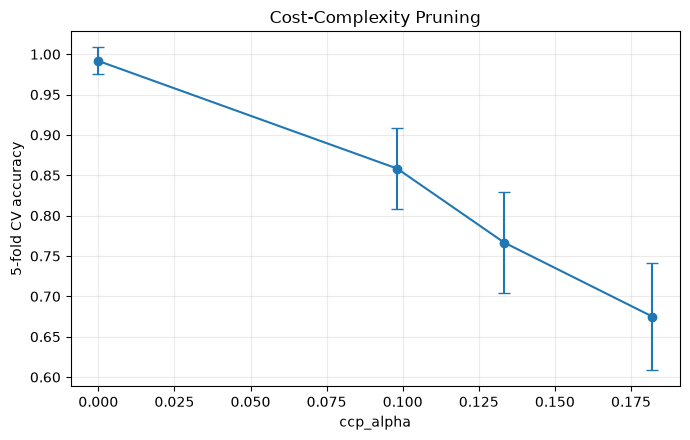

Selected ccp_alpha: 0.000000
Leaves after pruning: 6
Depth after pruning: 4


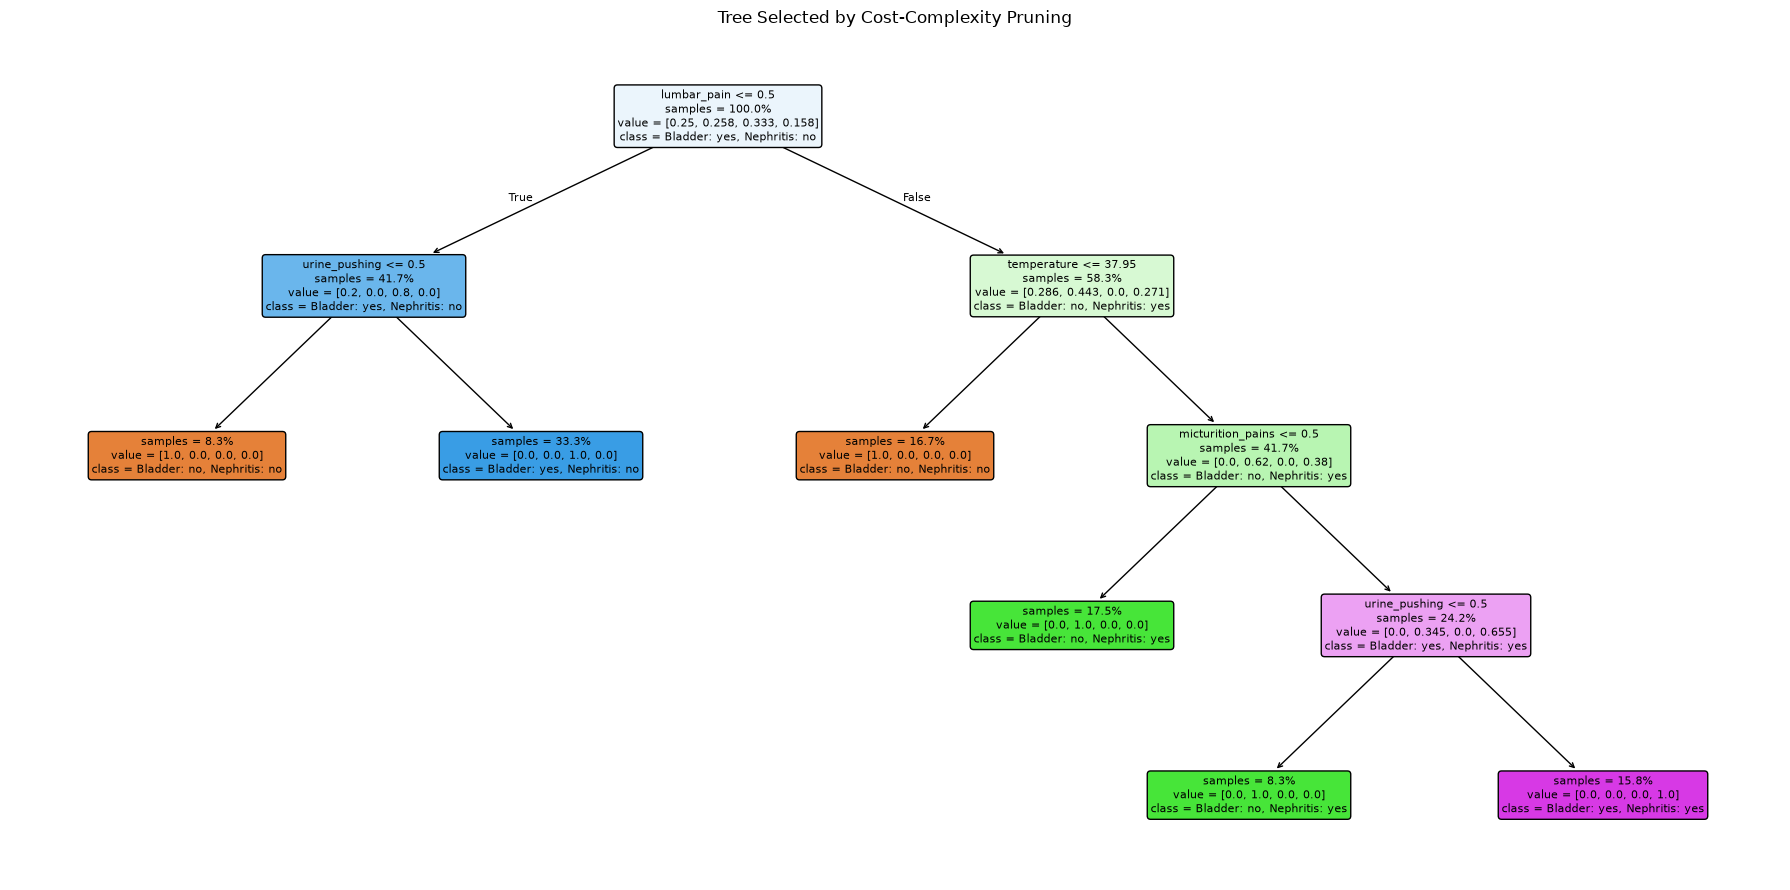

In [23]:
pruning_path = full_tree.cost_complexity_pruning_path(
    X_diagnosis, y_diagnosis
)
candidate_alphas = pruning_path.ccp_alphas[:-1]
tree_cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=RANDOM_SEED
)

pruning_rows = []
for alpha in candidate_alphas:
    model = DecisionTreeClassifier(
        random_state=RANDOM_SEED, ccp_alpha=alpha
    )
    scores = cross_val_score(
        model, X_diagnosis, y_diagnosis,
        cv=tree_cv, scoring="accuracy"
    )
    model.fit(X_diagnosis, y_diagnosis)
    pruning_rows.append({
        "ccp_alpha": alpha,
        "mean_cv_accuracy": scores.mean(),
        "std_cv_accuracy": scores.std(),
        "leaves": model.get_n_leaves(),
        "depth": model.get_depth(),
    })

pruning_results = pd.DataFrame(pruning_rows)
display(pruning_results.round(4))

best_row = pruning_results.sort_values(
    ["mean_cv_accuracy", "leaves"], ascending=[False, True]
).iloc[0]
best_alpha = float(best_row["ccp_alpha"])

plt.figure(figsize=(7, 4.5))
plt.errorbar(
    pruning_results["ccp_alpha"],
    pruning_results["mean_cv_accuracy"],
    yerr=pruning_results["std_cv_accuracy"],
    marker="o", capsize=4
)
plt.xlabel("ccp_alpha")
plt.ylabel("5-fold CV accuracy")
plt.title("Cost-Complexity Pruning")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

pruned_tree = DecisionTreeClassifier(
    random_state=RANDOM_SEED, ccp_alpha=best_alpha
)
pruned_tree.fit(X_diagnosis, y_diagnosis)

print(f"Selected ccp_alpha: {best_alpha:.6f}")
print(f"Leaves after pruning: {pruned_tree.get_n_leaves()}")
print(f"Depth after pruning: {pruned_tree.get_depth()}")

plt.figure(figsize=(18, 9))
plot_tree(
    pruned_tree,
    feature_names=X_diagnosis.columns,
    class_names=pruned_tree.classes_,
    filled=True,
    rounded=True,
    impurity=False,
    proportion=True,
    fontsize=8,
)
plt.title("Tree Selected by Cost-Complexity Pruning")
plt.tight_layout()
plt.show()

In [24]:
print_if_then_rules(pruned_tree, list(X_diagnosis.columns))

Rule 1: IF lumbar_pain <= 0.50 AND urine_pushing <= 0.50 THEN Bladder: no, Nephritis: no
Rule 2: IF lumbar_pain <= 0.50 AND urine_pushing > 0.50 THEN Bladder: yes, Nephritis: no
Rule 3: IF lumbar_pain > 0.50 AND temperature <= 37.95 THEN Bladder: no, Nephritis: no
Rule 4: IF lumbar_pain > 0.50 AND temperature > 37.95 AND micturition_pains <= 0.50 THEN Bladder: no, Nephritis: yes
Rule 5: IF lumbar_pain > 0.50 AND temperature > 37.95 AND micturition_pains > 0.50 AND urine_pushing <= 0.50 THEN Bladder: no, Nephritis: yes
Rule 6: IF lumbar_pain > 0.50 AND temperature > 37.95 AND micturition_pains > 0.50 AND urine_pushing > 0.50 THEN Bladder: yes, Nephritis: yes


The highest cross-validation accuracy occurs at $	ext{ccp_alpha}=0$. The
original tree already has only six leaves, and removing branches lowers the
validation accuracy noticeably. Therefore the minimal high-performing tree in
this pruning path is the original six-leaf tree, and its rules remain the same.

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [25]:
attribute_names = []
with open(DATA_DIR / "communities.names", encoding="utf-8") as file:
    for line in file:
        match = re.match(r"@attribute\s+(\S+)\s+", line)
        if match:
            attribute_names.append(match.group(1))

crime_data = pd.read_csv(
    DATA_DIR / "communities.data",
    header=None,
    names=attribute_names,
    na_values="?",
)

non_predictive = [
    "state", "county", "community", "communityname", "fold"
]
target_name = "ViolentCrimesPerPop"
X_crime = crime_data.drop(columns=non_predictive + [target_name])
y_crime = crime_data[target_name]

X_train_raw = X_crime.iloc[:1495].copy()
X_test_raw = X_crime.iloc[1495:].copy()
y_train = y_crime.iloc[:1495].copy()
y_test = y_crime.iloc[1495:].copy()

print("Complete data shape:", crime_data.shape)
print("Number of predictors used:", X_crime.shape[1])
print("Training set shape:", X_train_raw.shape)
print("Test set shape:", X_test_raw.shape)
display(crime_data.head())

Complete data shape: (1994, 128)
Number of predictors used: 122
Training set shape: (1495, 122)
Test set shape: (499, 122)


,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


The first 1495 rows are the training set and the remaining 499 rows are the
test set, as required. The five non-predictive columns from the data description
are removed, leaving 122 predictors.

### (b) Missing Values

In [26]:
missing_counts = X_crime.isna().sum()
missing_table = (
    missing_counts[missing_counts > 0]
    .sort_values(ascending=False)
    .rename("missing_count")
    .to_frame()
)
print("Total missing predictor values:", int(missing_counts.sum()))
print("Predictors containing missing values:", len(missing_table))
display(missing_table)

imputer = SimpleImputer(strategy="median")
imputer.fit(X_train_raw)

X_train = pd.DataFrame(
    imputer.transform(X_train_raw),
    columns=X_crime.columns,
    index=X_train_raw.index,
)
X_test = pd.DataFrame(
    imputer.transform(X_test_raw),
    columns=X_crime.columns,
    index=X_test_raw.index,
)
X_imputed = pd.concat([X_train, X_test]).sort_index()

print("Missing values after median imputation:",
      int(X_imputed.isna().sum().sum()))

Total missing predictor values: 36851
Predictors containing missing values: 23


,missing_count
PctPolicBlack,1675
PctPolicHisp,1675
LemasGangUnitDeploy,1675
LemasPctPolicOnPatr,1675
PolicOperBudg,1675
PolicCars,1675
PolicAveOTWorked,1675
NumKindsDrugsSeiz,1675
OfficAssgnDrugUnits,1675
PctPolicMinor,1675


Missing values after median imputation: 0


I used median imputation because several variables are strongly skewed. The
medians were learned from the training set only and then applied to both sets.

### (c) Plot a Correlation Matrix

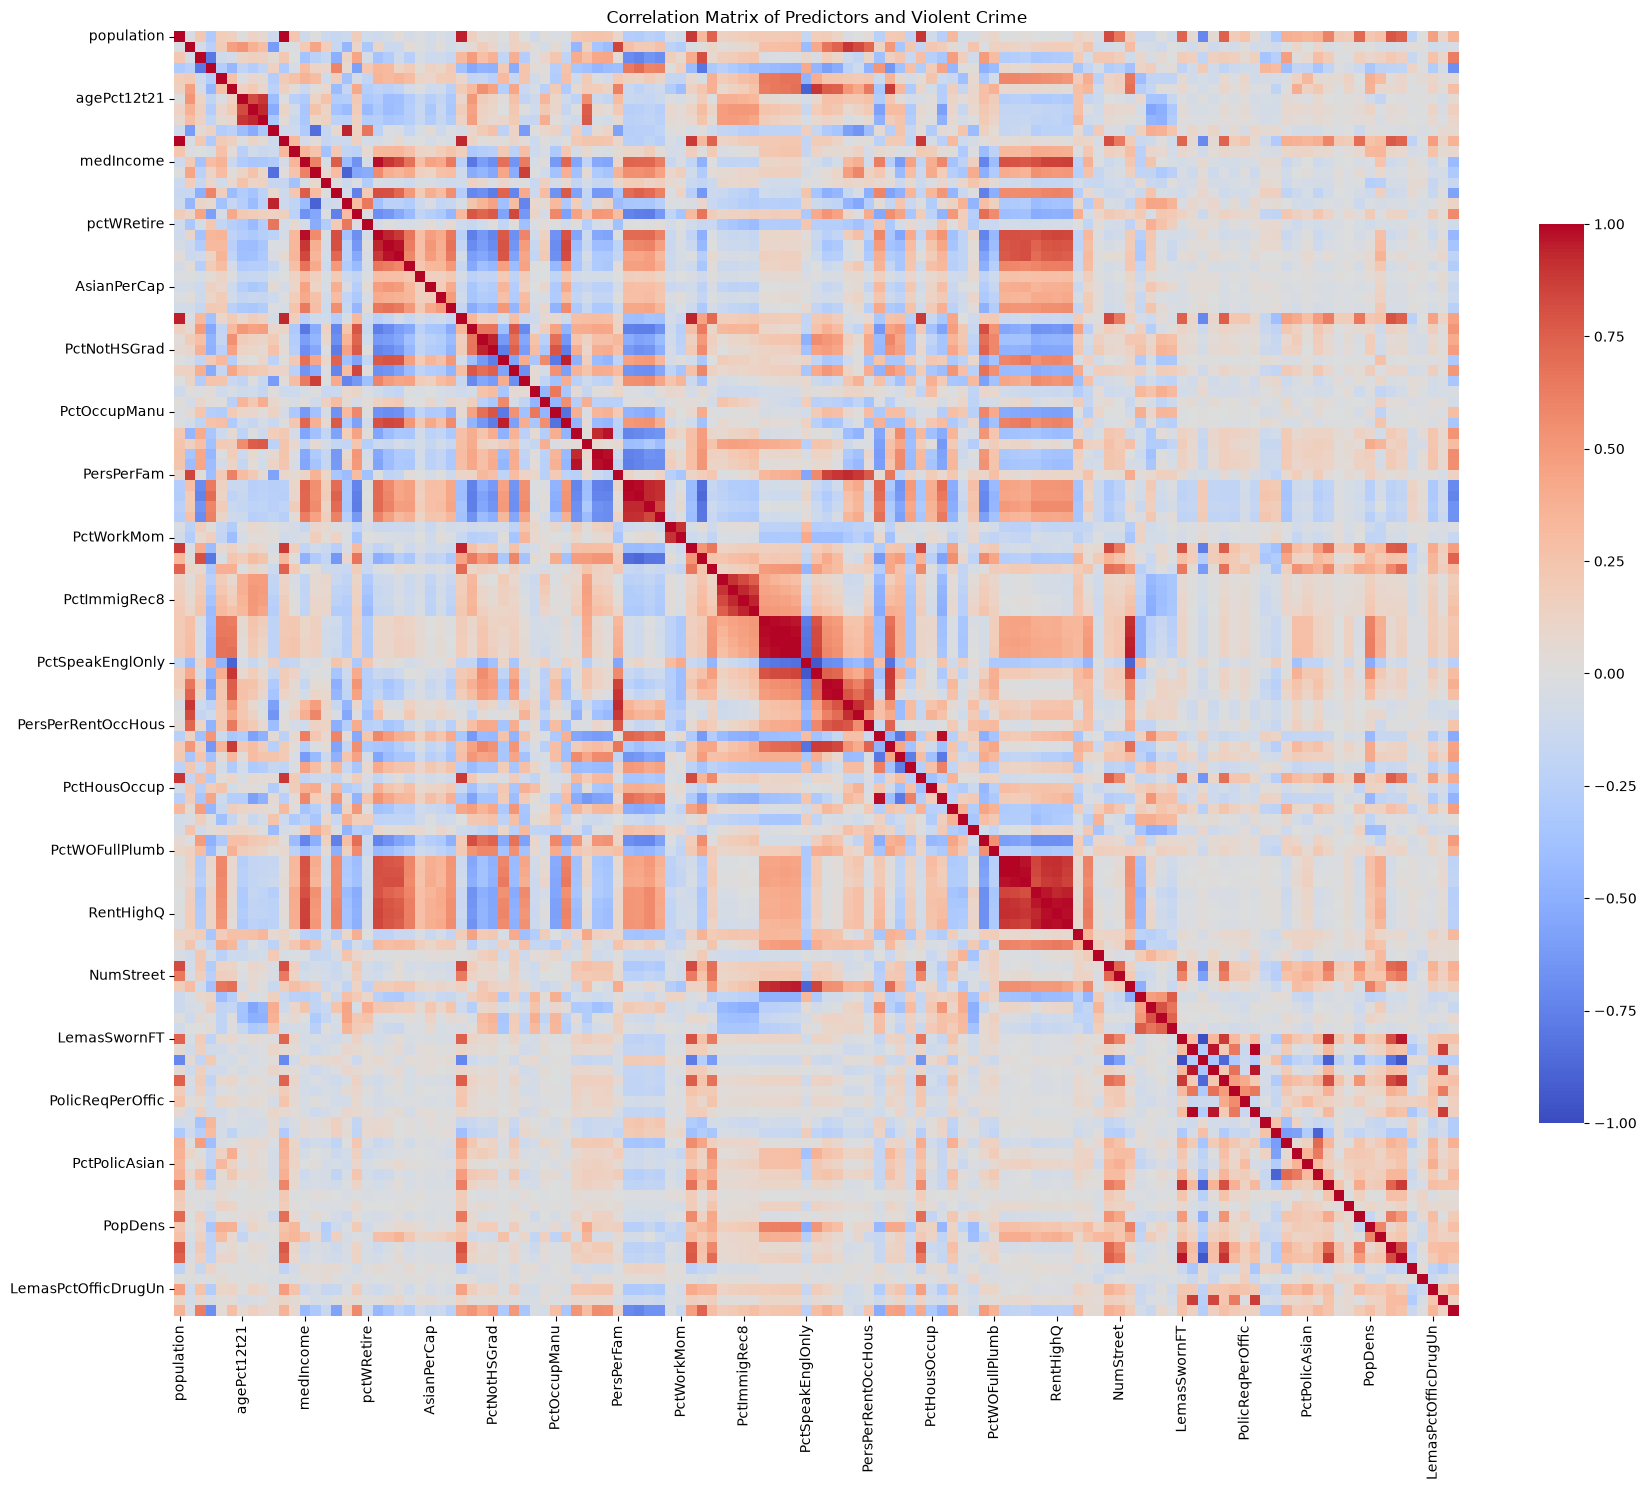

In [27]:
correlation_data = X_imputed.copy()
correlation_data[target_name] = y_crime.to_numpy()
correlation_matrix = correlation_data.corr()

plt.figure(figsize=(18, 15))
sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    xticklabels=6,
    yticklabels=6,
    cbar_kws={"shrink": 0.7},
)
plt.title("Correlation Matrix of Predictors and Violent Crime")
plt.tight_layout()
plt.show()

The heatmap has several blocks of strong positive or negative correlation. This
is reasonable because many variables describe related income, housing, family,
and police measurements. It also suggests that regularization can be helpful.

### (d) Calculate the Coefficient of Variation

In [28]:
feature_means = X_imputed.mean()
feature_stds = X_imputed.std(ddof=1)
cv_values = feature_stds / feature_means.replace(0, np.nan)

cv_table = pd.DataFrame({
    "mean": feature_means,
    "sample_std": feature_stds,
    "CV": cv_values,
}).sort_values("CV", ascending=False)

print("The table below shows the 20 largest CV values. CV was calculated for all 122 predictors.")
display(cv_table.head(20).round(4))

The table below shows the 20 largest CV values. CV was calculated for all 122 predictors.


,mean,sample_std,CV
PctPolicAsian,0.0184,0.1001,5.4478
NumStreet,0.0228,0.1004,4.4077
NumInShelters,0.0294,0.1026,3.4855
NumIlleg,0.0363,0.1087,2.9942
NumImmig,0.0301,0.0872,2.9005
LemasPctOfficDrugUn,0.0941,0.2403,2.5553
NumUnderPov,0.0555,0.1279,2.3050
population,0.0576,0.1269,2.2035
LemasSwornFT,0.0279,0.0581,2.0807
numbUrban,0.0641,0.1283,2.0017


### (e) Scatter Plots and Box Plots for the Highest-CV Features

floor(sqrt(128)) = 11
Selected features:
['PctPolicAsian', 'NumStreet', 'NumInShelters', 'NumIlleg', 'NumImmig', 'LemasPctOfficDrugUn', 'NumUnderPov', 'population', 'LemasSwornFT', 'numbUrban', 'HousVacant']


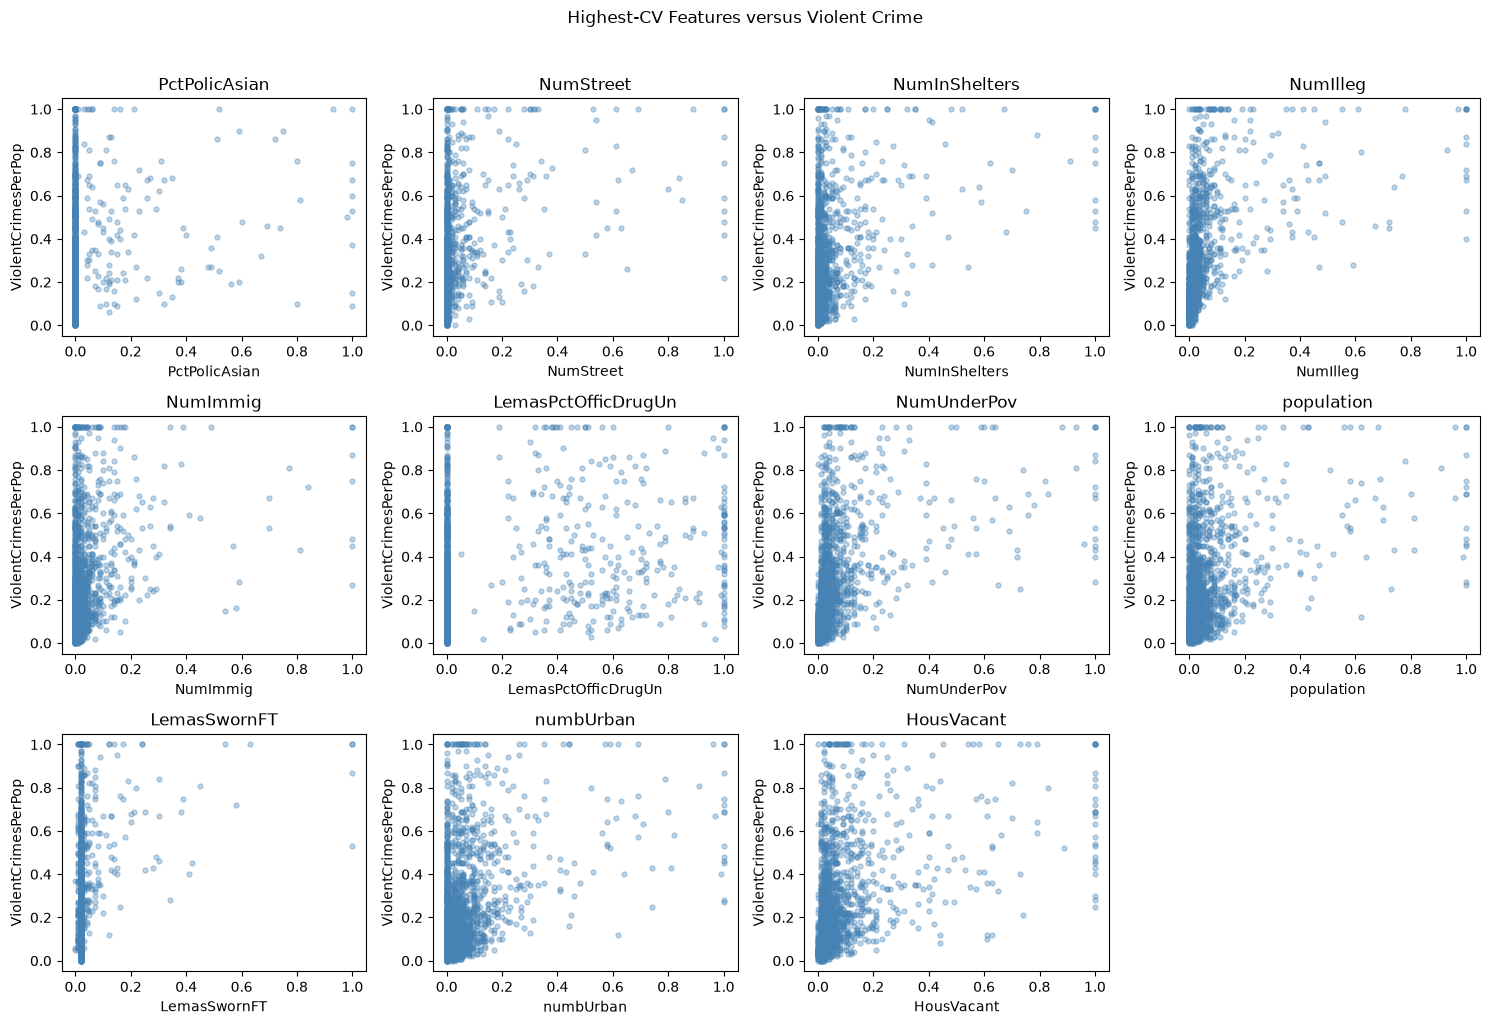

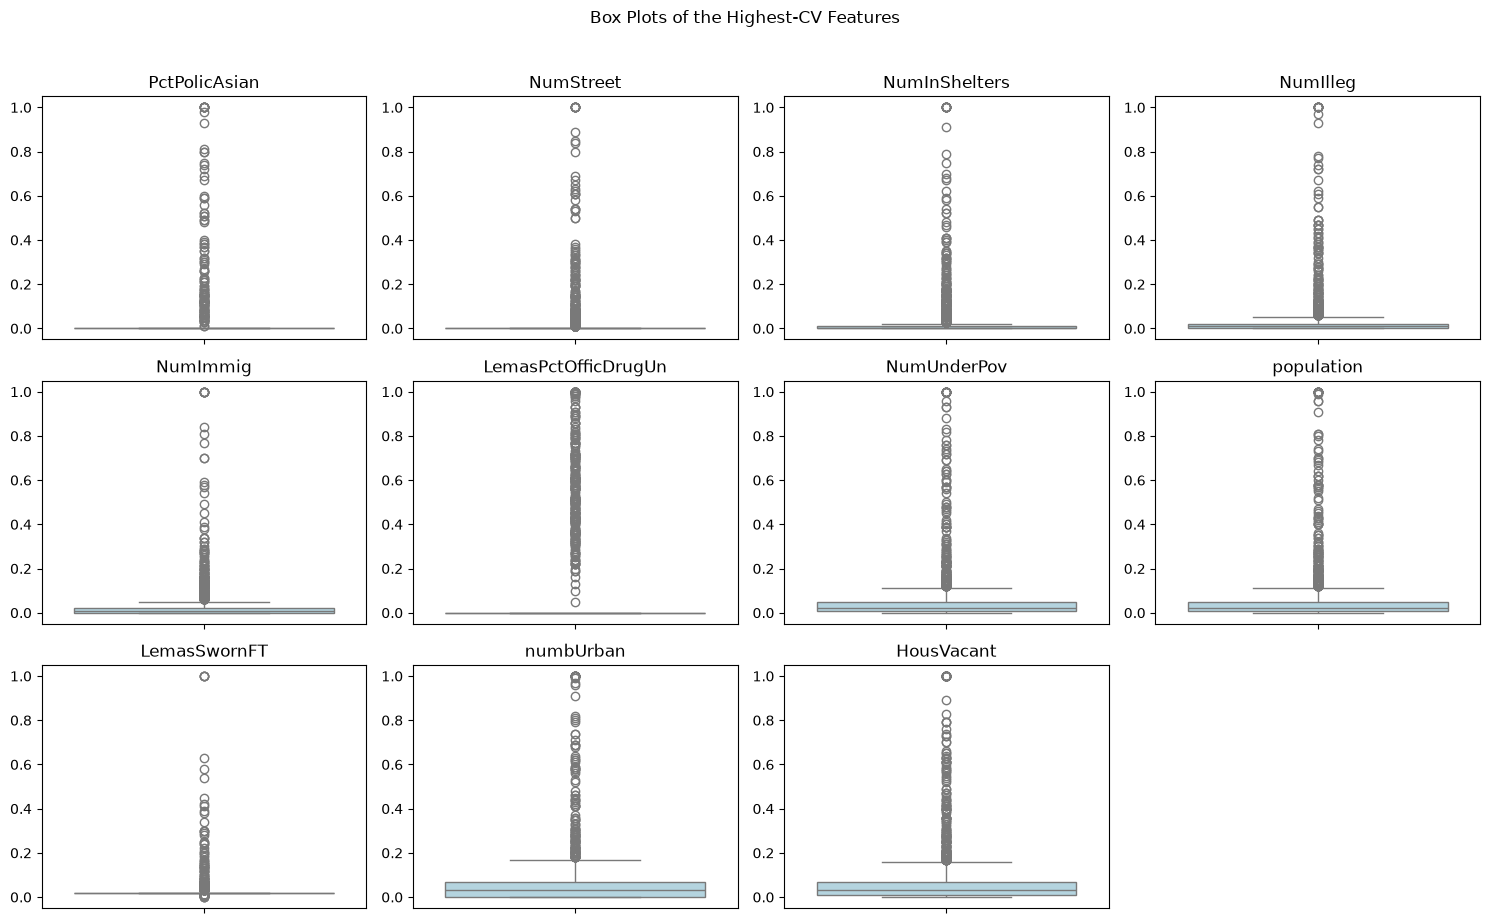

In [29]:
number_of_features = int(np.floor(np.sqrt(crime_data.shape[1])))
top_cv_features = cv_table.head(number_of_features).index.tolist()
print(f"floor(sqrt(128)) = {number_of_features}")
print("Selected features:")
print(top_cv_features)

fig, axes = plt.subplots(3, 4, figsize=(15, 10))
for feature, axis in zip(top_cv_features, axes.ravel()):
    axis.scatter(
        X_imputed[feature], y_crime,
        s=13, alpha=0.35, color="steelblue"
    )
    axis.set_title(feature)
    axis.set_xlabel(feature)
    axis.set_ylabel(target_name)
for axis in axes.ravel()[len(top_cv_features):]:
    axis.axis("off")
fig.suptitle("Highest-CV Features versus Violent Crime", y=1.02)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 4, figsize=(15, 9))
for feature, axis in zip(top_cv_features, axes.ravel()):
    sns.boxplot(y=X_imputed[feature], ax=axis, color="lightblue")
    axis.set_title(feature)
    axis.set_ylabel("")
for axis in axes.ravel()[len(top_cv_features):]:
    axis.axis("off")
fig.suptitle("Box Plots of the Highest-CV Features", y=1.02)
plt.tight_layout()
plt.show()

Most of these features have many observations near zero and a small number of
much larger values, which explains their high CV and long box-plot whiskers.
Some scatter plots, such as `NumIlleg`, `NumUnderPov`, and `HousVacant`, show a
positive pattern with violent crime. However, a scatter plot alone cannot prove
that a feature is significant because it does not control for the other highly
correlated predictors.

### (f) Fit a Linear Model

In [30]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
linear_prediction = linear_model.predict(X_test)
linear_mse = mean_squared_error(y_test, linear_prediction)

print(f"Least-squares test MSE: {linear_mse:.6f}")

Least-squares test MSE: 0.017966


I use mean squared error (MSE) as the test error for every regression model so
the results can be compared directly.

### (g) Fit a Ridge Regression Model

In [31]:
ridge_alphas = np.logspace(-4, 4, 100)
ridge_model = RidgeCV(
    alphas=ridge_alphas,
    cv=5,
    scoring="neg_mean_squared_error",
)
ridge_model.fit(X_train, y_train)
ridge_prediction = ridge_model.predict(X_test)
ridge_mse = mean_squared_error(y_test, ridge_prediction)

print(f"Selected ridge alpha: {ridge_model.alpha_:.6f}")
print(f"Ridge test MSE: {ridge_mse:.6f}")

Selected ridge alpha: 2.310130
Ridge test MSE: 0.017516


Ridge gives a slightly smaller test error than least squares. Shrinking the
coefficients helps when many predictors contain related information.

### (h) Fit LASSO Models

In [32]:
lasso_alphas = np.logspace(-5, 0, 100)

lasso_model = LassoCV(
    alphas=lasso_alphas,
    cv=5,
    max_iter=100000,
    random_state=RANDOM_SEED,
    n_jobs=-1,
)
lasso_model.fit(X_train, y_train)
lasso_prediction = lasso_model.predict(X_test)
lasso_mse = mean_squared_error(y_test, lasso_prediction)
lasso_selected = X_train.columns[np.abs(lasso_model.coef_) > 1e-8]

standardized_lasso = Pipeline([
    ("scale", StandardScaler()),
    ("lasso", Lasso(max_iter=100000)),
])
standardized_search = GridSearchCV(
    standardized_lasso,
    {"lasso__alpha": lasso_alphas},
    cv=5,
    scoring="neg_mean_squared_error",
    n_jobs=-1,
)
standardized_search.fit(X_train, y_train)
standardized_prediction = standardized_search.predict(X_test)
standardized_lasso_mse = mean_squared_error(
    y_test, standardized_prediction
)
standardized_coefficients = (
    standardized_search.best_estimator_.named_steps["lasso"].coef_
)
standardized_selected = X_train.columns[
    np.abs(standardized_coefficients) > 1e-8
]

lasso_comparison = pd.DataFrame({
    "model": ["LASSO", "Standardized LASSO"],
    "selected_alpha": [
        lasso_model.alpha_,
        standardized_search.best_params_["lasso__alpha"],
    ],
    "test_MSE": [lasso_mse, standardized_lasso_mse],
    "selected_variables": [
        len(lasso_selected), len(standardized_selected)
    ],
})
display(lasso_comparison.round(6))

selected_variable_table = pd.DataFrame({
    "LASSO": pd.Series(lasso_selected),
    "Standardized LASSO": pd.Series(standardized_selected),
})
display(selected_variable_table)

,model,selected_alpha,test_MSE,selected_variables
0,LASSO,0.000129,0.017610,74
1,Standardized LASSO,0.000830,0.017666,72


,LASSO,Standardized LASSO
0,racepctblack,racepctblack
1,racePctAsian,racePctAsian
2,agePct12t21,agePct12t21
3,agePct12t29,agePct12t29
4,pctUrban,pctUrban
...,...,...
69,PopDens,PolicCars
70,PctUsePubTrans,LemasPctPolicOnPatr
71,PolicCars,LemasGangUnitDeploy
72,LemasPctPolicOnPatr,NaN


The two LASSO test errors are very close. This is expected because the original
predictors are already normalized between 0 and 1. Standardization still changes
the scale used by the penalty, so the two fitted models do not select exactly the
same variables.

### (i) Fit a PCR Model

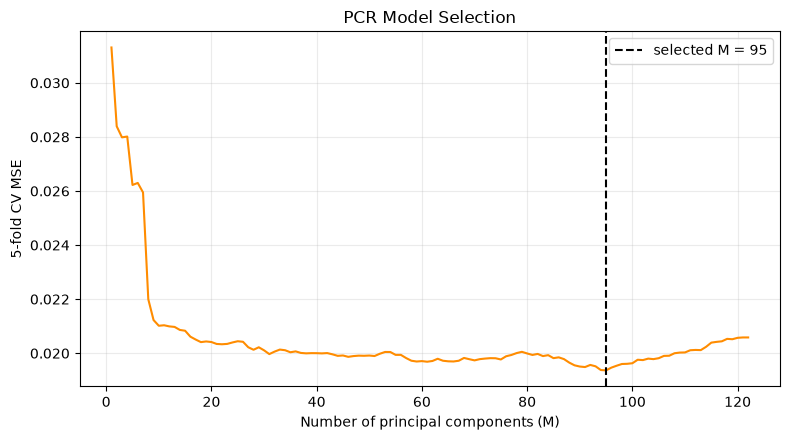

Selected number of components: 95
PCR test MSE: 0.018296


In [33]:
pcr_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("pca", PCA()),
    ("linear", LinearRegression()),
])

component_values = list(range(1, X_train.shape[1] + 1))
pcr_search = GridSearchCV(
    pcr_pipeline,
    {"pca__n_components": component_values},
    cv=5,
    scoring="neg_mean_squared_error",
    n_jobs=-1,
)
pcr_search.fit(X_train, y_train)
pcr_prediction = pcr_search.predict(X_test)
pcr_mse = mean_squared_error(y_test, pcr_prediction)
best_components = pcr_search.best_params_["pca__n_components"]

pcr_cv_mse = -pcr_search.cv_results_["mean_test_score"]
plt.figure(figsize=(8, 4.5))
plt.plot(component_values, pcr_cv_mse, color="darkorange")
plt.axvline(
    best_components, color="black", linestyle="--",
    label=f"selected M = {best_components}"
)
plt.xlabel("Number of principal components (M)")
plt.ylabel("5-fold CV MSE")
plt.title("PCR Model Selection")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print(f"Selected number of components: {best_components}")
print(f"PCR test MSE: {pcr_mse:.6f}")

PCR keeps the components that explain predictor variation, but those components
are not chosen using the response. In this data set it needs many components and
its test MSE is a little higher than the regularized linear models.

### (j) Fit a Boosting Tree

In [34]:
xgb_alphas = [0, 0.001, 0.01, 0.1, 1, 10, 100]
xgb_model = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    random_state=RANDOM_SEED,
    n_jobs=1,
)

xgb_search = GridSearchCV(
    xgb_model,
    {"reg_alpha": xgb_alphas},
    cv=5,
    scoring="neg_mean_squared_error",
    n_jobs=-1,
)
xgb_search.fit(X_train, y_train)
xgb_prediction = xgb_search.predict(X_test)
xgb_mse = mean_squared_error(y_test, xgb_prediction)

xgb_cv_table = pd.DataFrame({
    "alpha": xgb_alphas,
    "CV_MSE": -xgb_search.cv_results_["mean_test_score"],
})
display(xgb_cv_table.round(6))
print(f"Selected XGBoost alpha: {xgb_search.best_params_['reg_alpha']}")
print(f"XGBoost test MSE: {xgb_mse:.6f}")

,alpha,CV_MSE
0,0.000,0.020433
1,0.001,0.020339
2,0.010,0.020334
3,0.100,0.020506
4,1.000,0.020338
5,10.000,0.021857
6,100.000,0.056500


Selected XGBoost alpha: 0.01
XGBoost test MSE: 0.016072


In [35]:
model_comparison = pd.DataFrame({
    "model": [
        "Least Squares", "Ridge", "LASSO",
        "Standardized LASSO", "PCR", "XGBoost"
    ],
    "test_MSE": [
        linear_mse, ridge_mse, lasso_mse,
        standardized_lasso_mse, pcr_mse, xgb_mse
    ],
}).sort_values("test_MSE")

display(model_comparison.round(6))

,model,test_MSE
5,XGBoost,0.016072
1,Ridge,0.017516
2,LASSO,0.017610
3,Standardized LASSO,0.017666
0,Least Squares,0.017966
4,PCR,0.018296


XGBoost has the smallest test MSE in this run. Ridge and both LASSO models are
close to one another and slightly improve on least squares, while PCR has the
largest error of the fitted models. The result suggests that both regularization
and nonlinear tree splits are useful for these crime predictors.